
# FraudShield AI
## Dataset Profiling and Data Quality Assessment

### Project objective
FraudShield AI aims to identify potentially fraudulent financial transactions using machine learning.

### Dataset
IEEE-CIS Fraud Detection dataset from Kaggle.

### Objectives of this notebook
1. Understand the transaction and identity datasets.
2. Inspect dataset dimensions and data types.
3. Analyze the distribution of the fraud target.
4. Investigate missing values and data quality.
5. Validate the merged dataset.
6. Document findings before exploratory data analysis and preprocessing.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

PROJECT_ROOT = Path(r"D:\FraudShield")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"

TRANSACTION_FILE = RAW_DIR / "train_transaction.csv"
IDENTITY_FILE = RAW_DIR / "train_identity.csv"
MERGED_FILE = PROCESSED_DIR / "train_merged.parquet"

print("Project root:", PROJECT_ROOT)
print("Transaction file exists:", TRANSACTION_FILE.exists())
print("Identity file exists:", IDENTITY_FILE.exists())
print("Merged file exists:", MERGED_FILE.exists())


Project root: D:\FraudShield
Transaction file exists: True
Identity file exists: True
Merged file exists: True


In [2]:

transaction_sample = pd.read_csv(
    TRANSACTION_FILE,
    nrows=5,
    low_memory=False
)

identity_sample = pd.read_csv(
    IDENTITY_FILE,
    nrows=5,
    low_memory=False
)

print("Transaction dataset — sample shape:", transaction_sample.shape)
print("Identity dataset — sample shape:", identity_sample.shape)

print("\nTransaction columns and types:")
display(transaction_sample.dtypes.to_frame("data_type"))

print("\nIdentity columns and types:")
display(identity_sample.dtypes.to_frame("data_type"))

display(transaction_sample)
display(identity_sample)


Transaction dataset — sample shape: (5, 394)
Identity dataset — sample shape: (5, 41)

Transaction columns and types:


,data_type
TransactionID,int64
isFraud,int64
TransactionDT,int64
TransactionAmt,float64
ProductCD,object
...,...
V335,float64
V336,float64
V337,float64
V338,float64



Identity columns and types:


,data_type
TransactionID,int64
id_01,float64
id_02,float64
id_03,float64
id_04,float64
id_05,float64
id_06,float64
id_07,float64
id_08,float64
id_09,float64


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


,count,percentage
Legitimate,569877,96.501
Fraudulent,20663,3.499


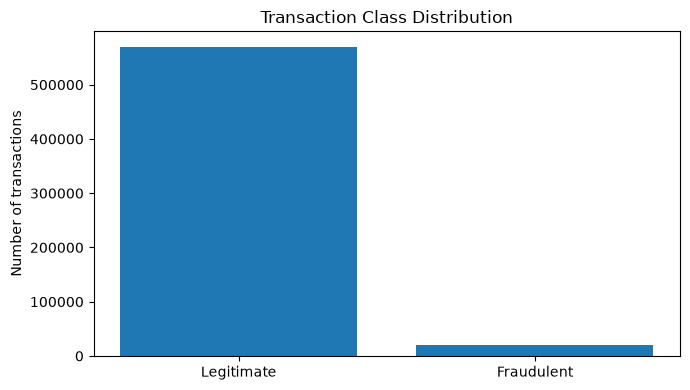

In [3]:

target_counts = pd.Series({
    "Legitimate": 569_877,
    "Fraudulent": 20_663
})

target_percentages = target_counts / target_counts.sum() * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

display(target_summary.round(3))

plt.figure(figsize=(7, 4))
plt.bar(target_summary.index, target_summary["count"])
plt.title("Transaction Class Distribution")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()


In [4]:

transaction_missing_file = REPORT_DIR / "train_transaction_missingness.csv"
identity_missing_file = REPORT_DIR / "train_identity_missingness.csv"

if transaction_missing_file.exists():
    transaction_missing = pd.read_csv(transaction_missing_file)
    print("Transaction dataset — top 20 missing columns")
    display(transaction_missing.head(20))
else:
    print("Transaction missingness report not found.")

if identity_missing_file.exists():
    identity_missing = pd.read_csv(identity_missing_file)
    print("Identity dataset — top 20 missing columns")
    display(identity_missing.head(20))
else:
    print("Identity missingness report not found.")

Transaction dataset — top 20 missing columns


,column,missing_count,missing_percentage
0,C1,0,0.000000
1,C10,0,0.000000
2,C11,0,0.000000
3,C12,0,0.000000
4,C13,0,0.000000
5,C14,0,0.000000
6,C2,0,0.000000
7,C3,0,0.000000
8,C4,0,0.000000
9,C5,0,0.000000


Identity dataset — top 20 missing columns


,column,missing_count,missing_percentage
0,DeviceInfo,25567,17.726179
1,DeviceType,3423,2.373243
2,TransactionID,0,0.000000
3,id_01,0,0.000000
4,id_02,3361,2.330257
5,id_03,77909,54.016071
6,id_04,77909,54.016071
7,id_05,7368,5.108401
8,id_06,7368,5.108401
9,id_07,139078,96.425922


In [5]:

df = pd.read_parquet(MERGED_FILE)

validation = {
    "Rows": len(df),
    "Columns": len(df.columns),
    "Duplicate TransactionIDs": int(df["TransactionID"].duplicated().sum()),
    "Missing target values": int(df["isFraud"].isna().sum()),
    "Legitimate transactions": int((df["isFraud"] == 0).sum()),
    "Fraudulent transactions": int((df["isFraud"] == 1).sum()),
    "Fraud rate (%)": round(df["isFraud"].mean() * 100, 4),
    "Memory usage (MB)": round(
        df.memory_usage(deep=True).sum() / (1024**2), 2
    )
}

display(pd.Series(validation, name="value").to_frame())

assert len(df) == 590_540, "Unexpected merged row count"
assert len(df.columns) == 434, "Unexpected merged column count"
assert df["TransactionID"].is_unique, "Duplicate transaction IDs found"
assert df["isFraud"].notna().all(), "Missing target labels found"

print("Merged dataset validation passed.")

,value
Rows,590540.000
Columns,434.000
Duplicate TransactionIDs,0.000
Missing target values,0.000
Legitimate transactions,569877.000
Fraudulent transactions,20663.000
Fraud rate (%),3.499
Memory usage (MB),2427.430


Merged dataset validation passed.



## Key Findingsm

1. The transaction dataset contains 590,540 records and 394 columns.
2. The identity dataset contains 144,233 records and 41 columns.
3. The merged dataset contains 590,540 records and 434 columns.
4. There are 20,663 fraudulent transactions and 569,877 legitimate transactions.
5. The fraud rate is approximately 3.499%, indicating substantial class imbalance.
6. Several transaction and identity attributes contain substantial missingness.
7. All transaction records were retained during the left join.
8. The next stage is exploratory data analysis and evidence-based preprocessing.

## Conclusion

The dataset is suitable for further investigation, but class imbalance,
missing values, temporal validation, and potential data leakage must be
considered before building and evaluating a fraud detection model.
